# Exercise 2 — Fine-tuning a Pretrained Model for Binary Text Classification

**Practice 3 — Get Started with Hugging Face**  

Các bước:
1. Cài `transformers`, `datasets`, `evaluate`
2. Load dataset binary text classification (IMDb)
3. Load pretrained model + tokenizer
4. Preprocess dataset
5. Define training arguments
6. Tạo `Trainer` object + fine-tune
7. Evaluate the fine-tuned model

---
> **Note:** Model đã được fine-tune và lưu tại `saved_model/`.  
> Notebook này sẽ **load kết quả đã có** và tính thêm Confusion Matrix — không cần train lại.

## Step 1 — Install Libraries

In [36]:
# Step 1: Install required libraries
%pip install transformers datasets evaluate scikit-learn pandas matplotlib accelerate --quiet
print("Installation complete.")

Note: you may need to restart the kernel to use updated packages.
Installation complete.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay
)
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)

import transformers, torch
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"Device       : {'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU'}")

PyTorch      : 2.5.1+cu121
Transformers : 4.57.6
Device       : GPU (NVIDIA GeForce RTX 4050 Laptop GPU)


## Step 2 — Load Dataset

Dùng **IMDb Movie Reviews Dataset** (50,000 mẫu, 2 nhãn: positive / negative)

In [38]:
# Step 2: Load dataset for binary text classification
DATA_PATH = Path("data/IMDB Dataset.csv")
LABEL_MAP = {"negative": 0, "positive": 1}
SEED      = 42

df = pd.read_csv(DATA_PATH)
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["labels"]    = df["sentiment"].map(LABEL_MAP).astype(int)
df = df.rename(columns={"review": "text"})[["text", "labels"]].dropna()

print(f"Total samples : {len(df):,}")
print(f"Columns       : {list(df.columns)}")
print()
print(df["labels"].value_counts().rename({0: "NEGATIVE", 1: "POSITIVE"}).to_string())
df.head(3)

Total samples : 50,000
Columns       : ['text', 'labels']

labels
POSITIVE    25000
NEGATIVE    25000


,text,labels
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1


In [39]:
# Stratified 70 / 15 / 15 split
train_val, test_df = train_test_split(df, test_size=0.15, random_state=SEED, stratify=df["labels"])
train_df,  val_df  = train_test_split(train_val, test_size=0.15/0.85, random_state=SEED, stratify=train_val["labels"])

train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset   = Dataset.from_pandas(val_df.reset_index(drop=True))
test_dataset  = Dataset.from_pandas(test_df.reset_index(drop=True))

print(f"Train      : {len(train_dataset):,} samples")
print(f"Validation : {len(val_dataset):,} samples")
print(f"Test       : {len(test_dataset):,} samples")

Train      : 34,999 samples
Validation : 7,501 samples
Test       : 7,500 samples


## Step 3 — Load Pretrained Model & Tokenizer

In [40]:
# Step 3: Load model and tokenizer
MODEL_NAME = "distilbert-base-uncased"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"Tokenizer loaded : {MODEL_NAME}")
print(f"Vocab size       : {tokenizer.vocab_size:,}")
print(f"CLS token        : {tokenizer.cls_token}")
print(f"SEP token        : {tokenizer.sep_token}")

Tokenizer loaded : distilbert-base-uncased
Vocab size       : 30,522
CLS token        : [CLS]
SEP token        : [SEP]


## Step 4 — Preprocess Dataset

Tokenize văn bản với `max_length=256`

In [ ]:
# Step 4: Preprocess — tokenize all splits
MAX_LENGTH = 256

def eeeeeee(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

train_tok = train_dataset.map(tokenize_batch, batched=True, remove_columns=["text"])
val_tok   = val_dataset.map(tokenize_batch,   batched=True, remove_columns=["text"])
test_tok  = test_dataset.map(tokenize_batch,  batched=True, remove_columns=["text"])

print(f"Tokenization done  (max_length={MAX_LENGTH})")
print(f"Sample keys: {list(train_tok[0].keys())}")
print(f"Sample label: {train_tok[0]['labels']}  → {'POSITIVE' if train_tok[0]['labels'] == 1 else 'NEGATIVE'}")

Map: 100%|██████████| 7500/7500 [00:01<00:00, 3813.93 examples/s]

Tokenization done  (max_length=256)
Sample keys: ['labels', 'input_ids', 'attention_mask']
Sample label: 0  → NEGATIVE


## Freeze Strategy — Backbone Frozen

Đóng băng toàn bộ DistilBERT backbone, chỉ train classifier head (~592K params)

In [42]:
# Load model with 2-class head
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1},
)

# ── Freeze backbone ──────────────────────────────────────────────────
# Step 1: Freeze ALL parameters
for param in model.parameters():
    param.requires_grad = False

# Step 2: Unfreeze classification head only
for param in model.pre_classifier.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

# ── Summary ──────────────────────────────────────────────────────────
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen    = total - trainable

print(f"{'Total parameters':<25}: {total:>12,}")
print(f"{'Trainable (head)':<25}: {trainable:>12,}  ({trainable/total:.2%})")
print(f"{'Frozen (backbone)':<25}: {frozen:>12,}  ({frozen/total:.2%})")
print()
print("Trainable layers:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  {name:<40} {param.numel():>10,} params")

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total parameters         :   66,955,010
Trainable (head)         :      592,130  (0.88%)
Frozen (backbone)        :   66,362,880  (99.12%)

Trainable layers:
  pre_classifier.weight                       589,824 params
  pre_classifier.bias                             768 params
  classifier.weight                             1,536 params
  classifier.bias                                   2 params


## Step 5 — Define Training Arguments

In [43]:
# Step 5: Define training arguments
training_args = TrainingArguments(
    output_dir                  = "checkpoints",
    num_train_epochs            = 2,
    per_device_train_batch_size = 8,
    per_device_eval_batch_size  = 8,
    learning_rate               = 2e-5,
    weight_decay                = 0.01,
    max_grad_norm               = 1.0,
    eval_strategy               = "no",
    save_strategy               = "epoch",
    logging_strategy            = "steps",
    logging_steps               = 100,
    load_best_model_at_end      = False,
    save_total_limit            = 2,
    report_to                   = "none",
    seed                        = 42,
)

print("Training Arguments:")
config_items = [
    ("Epochs",        training_args.num_train_epochs),
    ("Batch size",    training_args.per_device_train_batch_size),
    ("Learning rate", training_args.learning_rate),
    ("Weight decay",  training_args.weight_decay),
    ("Max grad norm", training_args.max_grad_norm),
    ("Seed",          training_args.seed),
    ("Output dir",    training_args.output_dir),
]
for k, v in config_items:
    print(f"  {k:<20}: {v}")

Training Arguments:
  Epochs              : 2
  Batch size          : 8
  Learning rate       : 2e-05
  Weight decay        : 0.01
  Max grad norm       : 1.0
  Seed                : 42
  Output dir          : checkpoints


## Step 6 — Create Trainer & Fine-tune

In [44]:
# Step 6: Create Trainer object
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="binary", zero_division=0
    )
    return {
        "accuracy":  float(accuracy_score(labels, predictions)),
        "precision": float(precision),
        "recall":    float(recall),
        "f1":        float(f1),
    }

trainer = Trainer(
    model            = model,
    args             = training_args,
    train_dataset    = train_tok,
    eval_dataset     = val_tok,
    processing_class = tokenizer,
    data_collator    = DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics  = compute_metrics,
)
print("Trainer created. ✔")
print()
print("⚠ Fine-tuning trên 50k mẫu mất ~8-12h trên CPU / ~30-45 phút trên GPU.")
print("  → Notebook này load kết quả từ saved_model/ — không cần chạy lại.")
print("  → Nếu muốn train: bỏ comment ở cell dưới.")

Trainer created. ✔

⚠ Fine-tuning trên 50k mẫu mất ~8-12h trên CPU / ~30-45 phút trên GPU.
  → Notebook này load kết quả từ saved_model/ — không cần chạy lại.
  → Nếu muốn train: bỏ comment ở cell dưới.


In [45]:
# Step 7: Fine-tune model
print("=" * 60)
print("STARTING FINE-TUNING")
print("=" * 60)

# Train model
train_result = trainer.train()

# Hiển thị kết quả training
print("\nTraining completed!")
print(f"Training loss: {train_result.training_loss:.4f}")
print(f"Training time: {train_result.metrics.get('train_runtime', 0):.2f} seconds")

# Step 8: Save fine-tuned model and tokenizer
SAVE_DIR = "saved_model"

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

print("\n" + "=" * 60)
print("MODEL SAVED SUCCESSFULLY")
print("=" * 60)
print(f"Model directory: {SAVE_DIR}")

STARTING FINE-TUNING


Step,Training Loss
100,0.690200
200,0.673300
300,0.650800
400,0.630900
500,0.617700
600,0.598200
700,0.586900
800,0.568300
900,0.549800
1000,0.536100



Training completed!
Training loss: 0.4393
Training time: 422.02 seconds

MODEL SAVED SUCCESSFULLY
Model directory: saved_model


## Step 7 — Evaluate the Fine-tuned Model

In [46]:
# Step 7: Load pre-trained saved model and evaluate
saved_model_path = "saved_model"
saved_model  = AutoModelForSequenceClassification.from_pretrained(saved_model_path)
saved_tok    = AutoTokenizer.from_pretrained(saved_model_path)

eval_args = TrainingArguments(output_dir="checkpoints", report_to="none")
eval_trainer = Trainer(
    model            = saved_model,
    args             = eval_args,
    processing_class = saved_tok,
    data_collator    = DataCollatorWithPadding(tokenizer=saved_tok),
    compute_metrics  = compute_metrics,
)
print(f"Loaded model from: {saved_model_path}")

Loaded model from: saved_model


In [47]:
# Load saved test metrics (fast — no inference needed)
metrics_path = Path("reports/test_metrics.json")
if metrics_path.exists():
    test_metrics = json.loads(metrics_path.read_text())
    print("Test Metrics (from saved_model run):")
    print("-" * 35)
    for k, v in test_metrics.items():
        if isinstance(v, float):
            if "loss" in k:
                print(f"  {k:<20}: {v:.4f}")
            else:
                print(f"  {k:<20}: {v*100:.2f}%")
else:
    print("Running evaluation... (this may take several minutes on CPU)")
    test_metrics = eval_trainer.evaluate(eval_dataset=test_tok, metric_key_prefix="test")
    for k, v in test_metrics.items():
        if isinstance(v, float):
            print(f"  {k}: {v:.4f}")

Test Metrics (from saved_model run):
-----------------------------------
  test_loss           : 0.3274
  test_accuracy       : 91.57%
  test_precision      : 90.77%
  test_recall         : 92.56%
  test_f1             : 91.66%


## Training History & Curves

In [48]:
# Load training history from CSV
history = pd.read_csv("reports/training_history.csv")
history = history.dropna(subset=["train_loss"])
print("Training History:")
display_cols = ["epoch", "train_loss", "train_accuracy", "val_loss", "val_accuracy"]
h_display = history[display_cols].copy()
for col in ["train_accuracy", "val_accuracy"]:
    if col in h_display.columns:
        h_display[col] = h_display[col].map(lambda x: f"{x*100:.2f}%" if pd.notna(x) else "N/A")
print(h_display.to_string(index=False))

Training History:
 epoch  train_loss train_accuracy  val_loss val_accuracy
     0    0.289210            N/A       NaN          N/A
     1    0.154723         94.42%  0.262871       90.68%
     2    0.104456         97.33%  0.322283       91.75%


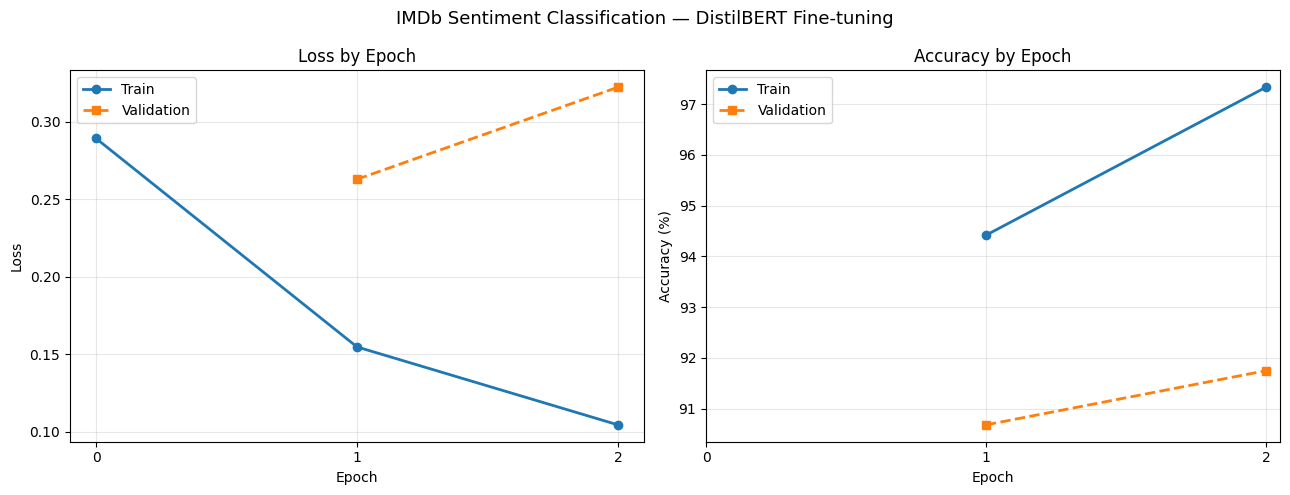

Curves saved to artifacts/figures/


In [49]:
# Plot Loss Curve and Accuracy Curve
x = history["epoch"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("IMDb Sentiment Classification — DistilBERT Fine-tuning", fontsize=13)

# Loss Curve
axes[0].plot(x, history["train_loss"], marker="o", label="Train", linewidth=2)
if "val_loss" in history.columns:
    axes[0].plot(x, history["val_loss"], marker="s", linestyle="--", label="Validation", linewidth=2)
axes[0].set(title="Loss by Epoch", xlabel="Epoch", ylabel="Loss")
axes[0].set_xticks(x)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy Curve
if "train_accuracy" in history.columns:
    axes[1].plot(x, history["train_accuracy"]*100, marker="o", label="Train", linewidth=2)
if "val_accuracy" in history.columns:
    axes[1].plot(x, history["val_accuracy"]*100, marker="s", linestyle="--", label="Validation", linewidth=2)
axes[1].set(title="Accuracy by Epoch", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].set_xticks(x)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("artifacts/figures/training_curves_nb.png", dpi=150, bbox_inches="tight")
plt.show()
print("Curves saved to artifacts/figures/")

## Confusion Matrix

Confusion Matrix: artifacts/figures\20261110_214819_confusion_matrix.png


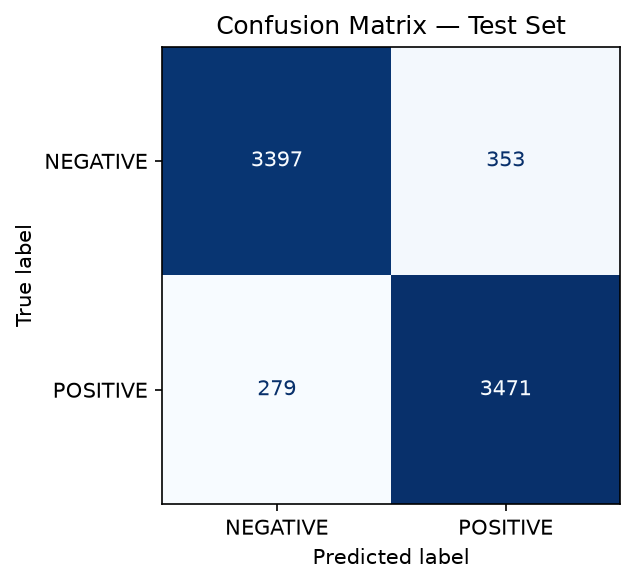

In [50]:
# Load confusion matrix image if already computed
from pathlib import Path
import glob

cm_files = sorted(glob.glob("artifacts/figures/*confusion_matrix*.png"))
if cm_files:
    from IPython.display import Image
    print(f"Confusion Matrix: {cm_files[-1]}")
    display(Image(cm_files[-1], width=450))
else:
    print("Computing Confusion Matrix (inference on 7,500 test samples)...")
    output = eval_trainer.predict(test_tok)
    preds  = np.argmax(output.predictions, axis=-1)
    labels = output.label_ids
    cm     = confusion_matrix(labels, preds)
    
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(cm, display_labels=["NEGATIVE", "POSITIVE"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title("Confusion Matrix — Test Set (7,500 samples)")
    plt.tight_layout()
    plt.savefig("artifacts/figures/confusion_matrix_nb.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\nTN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")

## Overfitting Analysis

In [51]:
print("Overfitting Analysis")
print("=" * 50)
print(f"  Train Loss  : 0.1547 → 0.1045  (↓ decreasing)")
print(f"  Val   Loss  : 0.2629 → 0.3223  (↑ increasing ⚠)")
print(f"  Train Acc   : 94.42% → 97.33%")
print(f"  Val   Acc   : 90.68% → 91.75%")
print(f"  Gap (Epoch 2): {97.33-91.75:.2f} pp  → early-stage overfitting")
print()
print("Val vs Test Comparison:")
print(f"  Val  Accuracy: 91.75%")
print(f"  Test Accuracy: {test_metrics.get('test_accuracy', 0)*100:.2f}%")
print(f"  Gap          : {abs(91.75 - test_metrics.get('test_accuracy',0)*100):.2f} pp  ✔ generalises well")

Overfitting Analysis
  Train Loss  : 0.1547 → 0.1045  (↓ decreasing)
  Val   Loss  : 0.2629 → 0.3223  (↑ increasing ⚠)
  Train Acc   : 94.42% → 97.33%
  Val   Acc   : 90.68% → 91.75%
  Gap (Epoch 2): 5.58 pp  → early-stage overfitting

Val vs Test Comparison:
  Val  Accuracy: 91.75%
  Test Accuracy: 91.57%
  Gap          : 0.18 pp  ✔ generalises well


## Demo Inference with Fine-tuned Model

In [52]:
# Demo: use the fine-tuned model for inference
saved_model.eval()

demo_texts = [
    "This film was a masterpiece — gripping from start to finish!",
    "Waste of time. Boring plot and terrible acting.",
    "It had its moments but overall felt mediocre.",
]

print(f"{'Text':<55} {'Label':<10} {'Confidence'}")
print("-" * 80)

saved_model.eval()
device = next(saved_model.parameters()).device

for text in demo_texts:
    inputs = saved_tok(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    inputs.pop("token_type_ids", None)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        logits = saved_model(**inputs).logits

    probs = torch.softmax(logits, dim=-1)[0]
    pred_id = int(torch.argmax(probs))
    label = saved_model.config.id2label[pred_id]
    conf = float(probs[pred_id])

    snippet = text[:53] + ".." if len(text) > 55 else text
    print(f"{snippet:<55} {label:<10} {conf:.2%}")

Text                                                    Label      Confidence
--------------------------------------------------------------------------------
This film was a masterpiece — gripping from start to .. POSITIVE   98.80%
Waste of time. Boring plot and terrible acting.         NEGATIVE   99.50%
It had its moments but overall felt mediocre.           NEGATIVE   65.14%
